# Which number carries the city head's slide, and how many drivers does the evening peak need?

**Week 4, Tuesday, the day's one notebook (chapters 1 and 4).** Uber, Hyderabad, the driver app's
peak-hour earnings guarantee, one day on. The city head takes the redesign to the Thursday city review
on one slide, in five minutes, with the driver-operations lead, the marketing lead and the finance
partner in the room. The number the slide must explain first: gross bookings (what riders paid) per
peak online hour fell from Rs 314 in the six weeks before the launch (31 August 2026) to Rs 260 in the
six weeks after, while the average peak fare stayed at Rs 165. In the afternoon the city head adds a
smaller ask: roughly how many drivers must be online at the weekday evening peak to keep the median
rider wait under five minutes, estimated without a dataset.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for this class.*

**What Monday found.** Peak online hours rose 24 percent while completed peak trips rose 3 percent, so
trips per peak online hour fell from 1.90 to 1.58, and 61 percent of the Rs 1.9 crore top-up (the gap
Uber pays up to the Rs 300 hourly floor) went to driver-weeks that accepted fewer than half the
requests offered to them.

**When to run it.** Cells 2 to 10 go with the morning's chapter 1: cells 3 and 4 after the twelve rows
on S13, cells 5 to 8 after the vote on S14, cells 9 and 10 with the makeover. Cells 11 to 15 go with
the afternoon's chapter 4, after the vote on S39.

**Who needs the answer.** The city head, whose one slide decides whether the scheme is kept, ended or
changed; a slide that quotes the wrong denominator hands each of the three roles a number to argue
with, and the city keeps paying for idle hours.

**The questions on the way.**

1. What do the twelve rows say when the same rupees are read three ways?
2. Which way does each read go over all the driver-weeks, and why does the per-driver-week read rise?
3. Is the fall in rupees per hour all trips, or some of it fare?
4. What does the twelve-week chart look like before and after the makeover?
5. How many drivers must be online at the evening peak, and which assumption moves the answer most?
6. Is the estimate sane when checked like for like against the case's own data?

In [1]:
# Load the two tables and define check, the one helper this notebook uses.
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)                                  # keep each table on one block

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

rows = pd.read_csv("../data/C2_W04_D02_twelve_rows_STUDENT.csv")    # six drivers, two weeks
weeks = pd.read_csv("../data/C2_W04_D02_twelve_weeks_STUDENT.csv")  # the city, week by week
print(len(rows), "driver-weeks in the twelve rows;", len(weeks), "weeks in the city table")

12 driver-weeks in the twelve rows; 12 weeks in the city table


## What do the twelve rows say when the same rupees are read three ways?

Each row is one driver in one week (the week of 10 August before the launch, the week of 21 September
after it): peak online hours, peak trips and the gross bookings those trips brought in. Gross bookings
are what riders paid for the trips, before Uber's share and before any top-up. The same rupees can be
divided by three things: the hours online, the driver-weeks, or the trips. The cell sums each column
per window and divides three times, exactly as the board did, then reads each driver's rupees per hour.

**Predict before you run.** The board found Rs 313.5 an hour before and Rs 196.2 after. Which drivers
explain most of that fall?

- a) A and B, the two in the busiest central zones
- b) C and D, the two who drove the most hours before
- c) E and F, Monday's two idle-tail drivers
- d) All six about equally

In [2]:
# Sum the twelve rows by window, then divide the same rupees by hours, driver-weeks and trips.
t = rows.groupby("window")[["peak_online_hours", "peak_trips", "peak_bookings_rs"]].sum()
t["driver_weeks"] = rows.groupby("window").size()
t["rs_per_hour"] = (t.peak_bookings_rs / t.peak_online_hours).round(1)
t["rs_per_driver_week"] = t.peak_bookings_rs / t.driver_weeks
t["rs_per_trip"] = t.peak_bookings_rs / t.peak_trips
t = t.loc[["before", "after"]]
print(t[["peak_online_hours", "peak_trips", "peak_bookings_rs", "rs_per_hour", "rs_per_driver_week", "rs_per_trip"]])
per_driver = (rows.assign(rs_per_hour=(rows.peak_bookings_rs / rows.peak_online_hours).round(1))
              .pivot(index="driver", columns="window", values="rs_per_hour")[["before", "after"]])
print(per_driver)                                            # rupees per peak online hour, driver by driver
check("hand count: Rs 313.5 and Rs 196.2 per hour", list(t.rs_per_hour) == [313.5, 196.2])
check("hand count: Rs 3,135 and Rs 2,420 per driver-week", list(t.rs_per_driver_week) == [3135, 2420])
check("E and F fall furthest", set(per_driver.after.nsmallest(2).index) == {"E", "F"})

        peak_online_hours  peak_trips  peak_bookings_rs  rs_per_hour  rs_per_driver_week  rs_per_trip
window                                                                                               
before                 60         114             18810        313.5              3135.0        165.0
after                  74          88             14520        196.2              2420.0        165.0
window  before  after
driver               
A        346.5  330.0
B        311.7  297.0
C        330.0  316.2
D        313.5  300.0
E        297.0   30.9
F        280.5   23.6
PASS hand count: Rs 313.5 and Rs 196.2 per hour
PASS hand count: Rs 3,135 and Rs 2,420 per driver-week
PASS E and F fall furthest


**What happened.** The answer is c. E and F fell from Rs 297.0 and Rs 280.5 an hour to Rs 30.9
and Rs 23.6, while A to D stayed near Rs 300 to Rs 330. Per peak online hour the six drivers fell from
Rs 313.5 to Rs 196.2, down 37 percent; per driver-week from Rs 3,135 to Rs 2,420, down 23 percent; per
trip they held at Rs 165, because each trip pays its fare whatever else happens. Three honest divisions
of the same rupees gave three sizes of change, so a slide that says "bookings fell" without its
denominator has said nothing a role cannot argue with.

## Which way does each read go over all the driver-weeks, and why does the per-driver-week read rise?

The city table holds every week's totals. An active driver-week is one enrolled driver with a row in
Monday's `driver_weeks` table that week; every driver in Monday's data is enrolled in the guarantee,
and a driver with no row that week is not counted. Rupees per driver-week is rupees per hour times
hours per driver-week, so the cell reads all three.

**Predict before you run.** About how many more peak online hours did an average active driver-week
carry after the launch?

- a) About 1 more
- b) About 4 more
- c) About 10 more
- d) Fewer than before

In [3]:
# The same three reads on every driver-week in the city, with hours per driver-week beside them.
w = weeks.groupby("window")[["peak_online_hours", "peak_trips", "peak_bookings_rs", "active_driver_weeks"]].sum()
w = w.loc[["before", "after"]]
w["rs_per_hour"] = w.peak_bookings_rs / w.peak_online_hours
w["rs_per_driver_week"] = w.peak_bookings_rs / w.active_driver_weeks
w["rs_per_trip"] = w.peak_bookings_rs / w.peak_trips
w["hours_per_driver_week"] = w.peak_online_hours / w.active_driver_weeks
change = (w.loc["after"] / w.loc["before"] - 1) * 100
print(w[["rs_per_hour", "rs_per_driver_week", "rs_per_trip", "hours_per_driver_week"]].round(1))
print((change[["rs_per_hour", "rs_per_driver_week", "hours_per_driver_week"]]).round(1).rename("change, percent"))
check("per hour down 16.9 percent, printed as 17", round(change.rs_per_hour, 1) == -16.9)
check("per active driver-week up 0.8 percent", round(change.rs_per_driver_week, 1) == 0.8)
check("rupees per driver-week is rupees per hour x hours per driver-week",
      ((w.rs_per_hour * w.hours_per_driver_week - w.rs_per_driver_week).abs() < 1e-6).all())

        rs_per_hour  rs_per_driver_week  rs_per_trip  hours_per_driver_week
window                                                                     
before        313.5              5816.5        165.0                   18.6
after         260.4              5861.3        165.0                   22.5
rs_per_hour             -16.9
rs_per_driver_week        0.8
hours_per_driver_week    21.3
Name: change, percent, dtype: float64
PASS per hour down 16.9 percent, printed as 17
PASS per active driver-week up 0.8 percent
PASS rupees per driver-week is rupees per hour x hours per driver-week


**What happened.** The answer is b: 18.6 hours a driver-week before the launch and 22.5 after,
up 21 percent. Per peak online hour the rupees fell from Rs 313.5 to Rs 260.4, down 17 percent, and per
active driver-week they rose from Rs 5,817 to Rs 5,861, up 0.8 percent, because each driver-week
carried about four more hours at 17 percent less per hour.

**The plausible wrong answer.** "Bookings per driver-week rose from Rs 5,817 to Rs 5,861, so the
guarantee is working; keep it as it is." That sentence is true to the rupee and would keep the city
paying for idle hours.

**Why it is wrong.** The rise was bought with hours, the very thing the scheme pays for. Bookings rose
3.0 percent and active driver-weeks 2.2 percent (6,360 to 6,500), so the ratio rose 0.8 percent. The
next cell splits the drivers into those there before the launch and the 140 who joined after it, to
see which group moved the read.

## Is the fall in rupees per hour all trips, or some of it fare?

Rupees per hour is also the average fare times the trips each online hour carried. The two routes
always agree, since the second is the first split in two; what the split shows is which half moved.

In [4]:
# Split the city by when drivers joined, then rebuild rupees per hour as fare x trips per hour.
groups = pd.read_csv("../data/C2_W04_D02_driver_groups_STUDENT.csv")  # Monday's rows, split by joined_month
groups["rs_per_driver_week"] = (groups.peak_bookings_rs / groups.driver_weeks).round(0).astype(int)
groups["hours_per_driver_week"] = (groups.peak_online_hours / groups.driver_weeks).round(1)
print(groups[["window", "group", "driver_weeks", "rs_per_driver_week", "hours_per_driver_week"]])
joiner = groups[groups.group == "the 140 joiners"].iloc[0]
check("the joiners sit below the after average, so they pull the read down",
      joiner.rs_per_driver_week < w.loc["after", "rs_per_driver_week"])
fare = w.peak_bookings_rs / w.peak_trips
trips_per_hour = w.peak_trips / w.peak_online_hours
second_route = fare * trips_per_hour
print(pd.DataFrame({"fare": fare, "trips_per_hour": trips_per_hour.round(3),
                    "fare_x_trips_per_hour": second_route.round(1)}))
check("second route agrees with bookings / hours in both windows",
      ((second_route - w.rs_per_hour).abs() < 1e-9).all())

   window                            group  driver_weeks  rs_per_driver_week  hours_per_driver_week
0  before  drivers there before the launch          6360                5817                   18.6
1   after  drivers there before the launch          6360                5895                   22.6
2   after                  the 140 joiners           140                4314                   16.4
PASS the joiners sit below the after average, so they pull the read down
         fare  trips_per_hour  fare_x_trips_per_hour
window                                              
before  165.0           1.900                  313.5
after   165.0           1.578                  260.4
PASS second route agrees with bookings / hours in both windows


**What happened.** The drivers who were there before the launch rose from Rs 5,817 to Rs 5,895 a
driver-week, up 1.4 percent, on 22.6 hours a week against 18.6. The 140 joiners drove about one week
each at Rs 4,314, below the average, so they pulled the read down to 0.8 percent. The fare held at Rs 165
in both windows, and trips per hour fell from 1.900 to 1.578 (printed elsewhere as 1.58): Rs 165 x
1.578 is Rs 260.4, so the whole fall in rupees per hour is the fall in trips per hour Monday found.
That is the evidence line the slide stands on when the finance partner asks whether riders paid less.

## What does the twelve-week chart look like before and after the makeover?

The cluttered version is the one dashboards send: four series in four units on one axis, two of them
divided by 20 or 100 to fit, a legend away from the lines, gridlines, and a title that names a topic.
The clear version keeps one series, the one the scheme pays per, draws the launch, labels the two
windows' values on the lines, and makes the title a sentence.

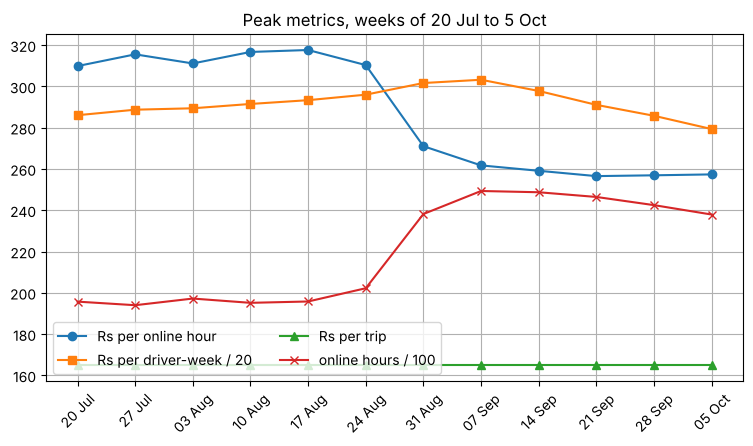

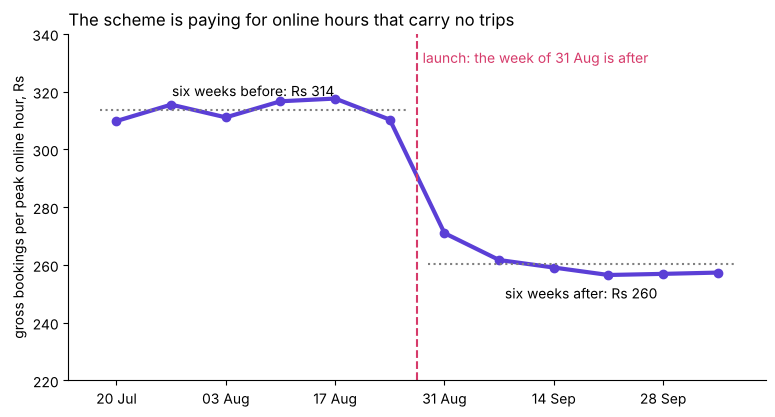

PASS every after week sits below every before week: a step at the launch, not a slow drift


In [5]:
# Draw the series cluttered, then the makeover: one series, the launch, two labels, a sentence title.
x = range(len(weeks))
labels = pd.to_datetime(weeks.week_start).dt.strftime("%d %b")

fig, ax = plt.subplots(figsize=(9, 4.5))                      # before: everything at once
ax.plot(x, weeks.rs_per_hour, marker="o", label="Rs per online hour")
ax.plot(x, weeks.rs_per_driver_week / 20, marker="s", label="Rs per driver-week / 20")
ax.plot(x, weeks.rs_per_trip, marker="^", label="Rs per trip")
ax.plot(x, weeks.peak_online_hours / 100, marker="x", label="online hours / 100")
ax.grid(True); ax.legend(loc="lower left", ncol=2)
ax.set_xticks(list(x), labels, rotation=45); ax.set_title("Peak metrics, weeks of 20 Jul to 5 Oct")
plt.show()

before, after = w.rs_per_hour
fig, ax = plt.subplots(figsize=(9, 4.5))                      # after: one claim, one series
ax.plot(x, weeks.rs_per_hour, color="#5B3FD6", lw=3, marker="o")
ax.hlines(before, -0.3, 5.3, color="gray", ls=":"); ax.hlines(after, 5.7, 11.3, color="gray", ls=":")
ax.text(2.5, before + 5, f"six weeks before: Rs {before:.0f}", ha="center")
ax.text(8.5, after - 12, f"six weeks after: Rs {after:.0f}", ha="center")
ax.axvline(5.5, color="#D63A6A", ls="--")
ax.text(5.6, 330, "launch: the week of 31 Aug is after", color="#D63A6A")
ax.set_ylim(220, 340); ax.set_xticks(list(x)[::2], labels[::2])
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("The scheme is paying for online hours that carry no trips", loc="left")
ax.set_ylabel("gross bookings per peak online hour, Rs")
plt.show()
step = weeks[weeks.window == "after"].rs_per_hour.max() < weeks[weeks.window == "before"].rs_per_hour.min()
check("every after week sits below every before week: a step at the launch, not a slow drift", step)

**What happened.** On the clear chart the eye finds the claim in a second: about Rs 314 an hour
before, about Rs 260 after, and the drop lands in the launch week, with the highest after week (Rs 271)
below the lowest before week (Rs 310). A season that ended slowly would drift; this steps. That helps
with the finance partner's monsoon objection without settling it, since last year's weeks are not in
the data.

## How many drivers must be online at the weekday evening peak, and which assumption moves the answer most?

**Afternoon, chapter 4: open this part after the vote on S39.**

**Clarify.** One city (the Hyderabad metro area), one platform (Uber) and one product, the three-hour
weekday evening peak, drivers online at one moment, and a median rider wait under five minutes.

**Map.** Drivers online = (trips to serve in an hour / trips one online driver completes in an hour)
x a buffer. Trips to serve in an hour = people x weekday Uber trips per person x the share of the day's
trips in the evening window / 3 hours; counting trips per person, never riders, keeps a commuter who
rides both ways in the count. Trips one online driver completes in an hour = the trips a busy driver
fits in an hour x (1 - the idle share), where the idle share is the share of online drivers with no
rider at that moment. The buffer covers the busiest half hour of the window.

Every value below is a guess said aloud, with the range it could take and the reason beside it.

**Predict before you run.** If people took 2 weekday Uber trips per 100 instead of 1, what would happen
to the answer?

- a) It doubles, to about 11,400
- b) It rises by about a quarter
- c) It does not change, since the buffer absorbs it
- d) It halves

                                                                          why
assumption                                                                   
people in the city                             the metro area, a round number
weekday Uber trips per person                     1 trip for every 100 people
share of trips in the evening                             the evening commute
trips a busy driver fits an hour           a peak trip takes about 25 minutes
idle share                        a guess, from a busy evening to a slack one
buffer for the busiest half hour                     the peak inside the peak
trips an hour: 8,333; drivers online: 5,704; at 2 trips per 100 people: 11,409
                                  lowest  highest
assumption                                       
buffer for the busiest half hour    5500     6200
people in the city                  5100     6300
idle share                          5100     6400
share of trips in the evening       4600     68

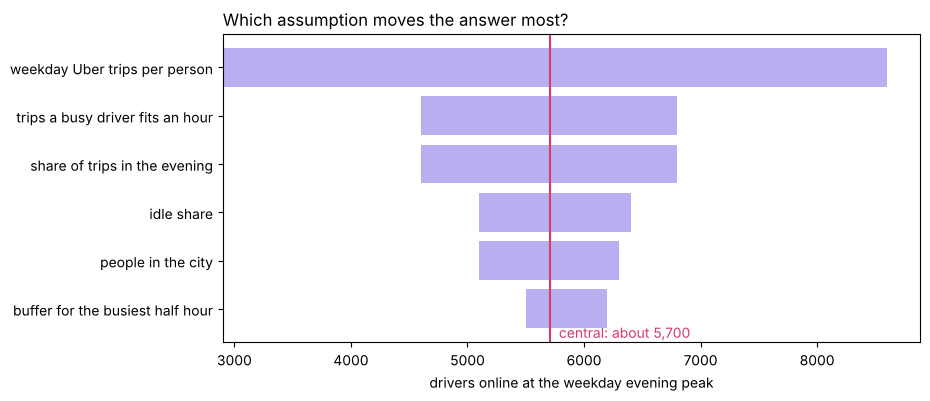

PASS about 5,700 drivers at the central values
PASS doubling trips per person doubles the answer
PASS trips per person moves the answer most


In [6]:
# The ledger: every guess with its range, then the chain run on every version of the ledger.
ledger = pd.DataFrame([   # assumption: central, low, high, and why
    ("people in the city",               10_000_000, 9_000_000, 11_000_000, "the metro area, a round number"),
    ("weekday Uber trips per person",    0.01,       0.005,     0.015,      "1 trip for every 100 people"),
    ("share of trips in the evening",    0.25,       0.20,      0.30,       "the evening commute"),
    ("trips a busy driver fits an hour", 2.4,        2.0,       3.0,        "a peak trip takes about 25 minutes"),
    ("idle share",                       0.30,       0.22,      0.38,       "a guess, from a busy evening to a slack one"),
    ("buffer for the busiest half hour", 1.15,       1.10,      1.25,       "the peak inside the peak"),
], columns=["assumption", "central", "low", "high", "why"]).set_index("assumption")

versions = pd.DataFrame([ledger.central.values], index=["central"], columns=ledger.index)
for name in ledger.index:                       # one row per version: one guess moved to an end
    for end in ("low", "high"):
        versions.loc[f"{name}, {end}"] = ledger.central
        versions.loc[f"{name}, {end}", name] = ledger.loc[name, end]
versions.loc["2 trips per 100 people"] = ledger.central
versions.loc["2 trips per 100 people", "weekday Uber trips per person"] = 0.02

v = versions                                    # the chain, run down every row at once
trips_an_hour = v["people in the city"] * v["weekday Uber trips per person"] * v["share of trips in the evening"] / 3
versions["drivers"] = (trips_an_hour / (v["trips a busy driver fits an hour"] * (1 - v["idle share"]))
                       * v["buffer for the busiest half hour"])
central = versions.loc["central", "drivers"]
doubled = versions.loc["2 trips per 100 people", "drivers"]
ends = pd.DataFrame({end: [versions.loc[f"{name}, {end}", "drivers"] for name in ledger.index]
                     for end in ("low", "high")}, index=ledger.index)
swing = pd.DataFrame({"lowest": ends.min(axis=1), "highest": ends.max(axis=1)}).round(-2).astype(int)
swing["width"] = swing.highest - swing.lowest
swing = swing.sort_values("width")
print(ledger[["why"]])
print(f"trips an hour: {10_000_000 * 0.01 * 0.25 / 3:,.0f}; drivers online: {central:,.0f}; "
      f"at 2 trips per 100 people: {doubled:,.0f}")
print(swing[["lowest", "highest"]])

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(swing.index, swing.width, left=swing.lowest, color="#B9AEF0")
ax.axvline(central, color="#D63A6A")
ax.text(central + 80, -0.6, f"central: about {round(central, -2):,.0f}", color="#D63A6A")
ax.set_xlabel("drivers online at the weekday evening peak")
ax.set_title("Which assumption moves the answer most?", loc="left")
plt.show()
check("about 5,700 drivers at the central values", round(central, -2) == 5700)
check("doubling trips per person doubles the answer", abs(doubled / central - 2) < 1e-9)
check("trips per person moves the answer most", swing.index[-1] == "weekday Uber trips per person")

**What happened.** The answer is a: the chain is a product, so doubling one factor doubles the
answer, to about 11,400. At the central values, about 8,333 trips an hour divided by 1.68 trips per
online driver-hour (2.4 x 0.70), times 1.15, is about 5,700 drivers. Moving trips per person from 0.5
to 1.5 per 100 moves the answer from about 2,900 to about 8,600 with everything else held, wider than
any other assumption; the idle share moves it from about 5,100 to 6,400.

## Is the estimate sane when checked like for like against the case's own data?

**Validate.** Monday's tables are a slice of the city, the twelve zones the enrolled drivers work, so
their absolute count cannot check a city total. Monday's data counts peak hours on all seven days, two
three-hour windows a day, 42 hours a week, so its 256,556 after-window requests are about 1,018 an hour,
far below the city's 8,333 trips. What the slice can check is a ratio in the middle of the chain,
counted the same way on both sides: online driver-hours per completed trip. No source in the research
ledger holds a published count of Uber drivers online at Hyderabad's evening peak, so that slot stays
"to be found".

In [7]:
# Check the chain like for like against the case's driver-hours per trip, then a month's own days.
case = weeks.groupby("window")[["peak_online_hours", "peak_trips"]].sum().loc[["before", "after"]]
per_trip = case.peak_online_hours / case.peak_trips          # online driver-hours per completed trip
case["driver_hours_per_trip"] = per_trip.round(2)
chain = 1 / (2.4 * (1 - 0.30))
case_tph_before = 1 / per_trip["before"]
checked = 10_000_000 * 0.01 * 0.25 / 3 / case_tph_before * 1.15
print(case)
print(f"the chain: {chain:.2f} driver-hours per trip before its buffer, "
      f"{chain / per_trip['before']:.2f} times the case's before window")
print(f"re-run at the case's {case_tph_before:.2f} trips an hour: about {round(checked, -2):,.0f} drivers")
check("the chain runs high, by about an eighth", 1.1 < chain / per_trip["before"] < 1.15)

month_total, days = 9e9, 30                 # an invented payments network: 9 billion in a 30-day month
per_day, over_31 = month_total / days, month_total / 31
print(f"per day: {per_day / 1e6:,.0f} million; over 31 days: {over_31 / 1e6:,.0f} million "
      f"({over_31 / per_day - 1:+.1%})")
check("the per-day figure divides by the month's own days", round(per_day / 1e6) == 300)

        peak_online_hours  peak_trips  driver_hours_per_trip
window                                                      
before             118000      224200                   0.53
after              146300      230900                   0.63
the chain: 0.60 driver-hours per trip before its buffer, 1.13 times the case's before window
re-run at the case's 1.90 trips an hour: about 5,000 drivers
PASS the chain runs high, by about an eighth
per day: 300 million; over 31 days: 290 million (-3.2%)
PASS the per-day figure divides by the month's own days


**What happened.** Before the launch the case's twelve zones used 0.53 online driver-hours per
completed trip, with a median wait of 4.8 minutes; after it, 0.63. The chain puts 0.60 behind each
trip before its buffer, about an eighth more than the window whose wait met the target, so the chain
errs high. Re-run at the case's 1.90 trips an hour it gives about 5,000 drivers, so the honest answer
is about 5,000 to 5,700. The invented network shows the per-day check: 9 billion over its 30 days is
300 million a day, and dividing by 31 gives 290 million, 3.2 percent low for no reason but the
calendar. The afternoon's paired drill on UPI meets the published figure only after the swap.

**The answers, one line each.**

1. On the twelve rows the same rupees fell 37 percent per hour, 23 percent per driver-week and 0 per trip, and E and F explain most of the fall.
2. Over all driver-weeks, per hour fell 17 percent and per active driver-week rose 0.8 percent, because each driver-week carried about four more hours; the 140 joiners pulled it down.
3. The fall is all trips: Rs 165 x 1.90 is Rs 313.5, and Rs 165 x 1.578 is Rs 260.4.
4. The clear chart carries one series, a launch line and a sentence for a title; the drop is a step at the launch.
5. About 5,700 drivers before the check, from about 2,900 to 8,600 with everything else held, driven by trips per person.
6. Like for like, the chain's 0.60 driver-hours per trip runs an eighth above the case's 0.53, so say about 5,000 to 5,700.

### What will an interviewer ask about this, and what does a strong answer do?

**[S] Present this recommendation to a non-technical leader in two minutes.** Name the decision, open on
the claim ("the scheme is paying for online hours that carry no trips"), give one number with its
denominator (Rs 314 to Rs 260 per peak online hour), say what riders got (a median wait of 4.8 to 4.6
minutes), say the caveat (the monsoon ended inside the six weeks), and end on the action with its cost
and signer (test paying per completed peak trip with an acceptance floor; city-wide it saves Rs 58 lakh
to Rs 92.7 lakh over six weeks if a half to a fifth of the idle drivers' top-up is still paid; the city
head signs the test).

**[S] How many drivers must be online at the evening peak?** Clarify the city, the product, the window,
the unit (online at one moment) and the wait target; say the formula; say each assumption aloud with
its range; give the range with everything else held and the factor that drives it; check the ratio like
for like and move the answer if the check says so; and say what the number decides.

**The AI-company variant.** A coding assistant's dashboard reports suggestions accepted per developer-week.
The same trap waits: accepted text can be deleted soon after. A read that matches what the product
promises is suggested code still in the file seven days after acceptance, per developer who saw a
suggestion, with ratio guardrails against padding and acceptance kept as a leading input.